# Day 21

## UK National Parks: visitor centres and the shortest road trip
1. Draw the 15 National Park boundaries from OpenStreetMap as dashed white outlines
2. Plot one hand-picked OSM visitor centre per park
3. Find the shortest *road* route that visits every park once (exact solution, starts and ends in different parks)
4. Draw each leg along real roads, coloured by how long that leg is, and print the trip statistics
5. Animate it: a car drives the route with the camera following, then zooms out to the full map

Routing uses the public OSRM demo server (OpenStreetMap road data). It is free but rate-limited, so the code only makes about 15 requests.

Install once, then restart the kernel:
`pip install requests numpy matplotlib pyproj contextily shapely imageio-ffmpeg`

## 1. Imports and config

In [137]:
import json, os, re, time
import numpy as np
import requests
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from pyproj import Transformer
import contextily as ctx
from shapely import wkt
from shapely.geometry import LineString
from shapely.ops import unary_union, polygonize, transform

In [138]:
OSRM = "https://router.project-osrm.org"
OVERPASS = "https://overpass-api.de/api/interpreter"
HEADERS = {"User-Agent": "30DayMapChallenge-UK-NationalParks/1.0"}

In [139]:
ZOOM = 8             # basemap detail: 8 is fine, 9 is sharper but slower
CMAP = LinearSegmentedColormap.from_list(
    "bright_plasma",
    ["#8B5CF6", "#C84BCE", "#F05A8D", "#FF9E45", "#F9F871"]
)
OUT_PNG = "uk_national_parks_roadtrip.png"
BOUNDARY_CACHE = "park_boundaries.json"   # saved after the first download, delete it to refetch

In [140]:
BASEMAP = ctx.providers.OpenStreetMap.HOT
BG, FG, CASING, BND = "#000000", "#ffffff", "#000000", "#666666"

## 2: The 15 parks (rough seed coordinates)
These are only fallbacks. Cell 3 replaces them with the visitor centres picked on OpenStreetMap.

In [142]:
PARKS = [
    # name,                 visitor centre,                              lat,      lon
    ("Dartmoor",            "High Moorland Visitor Centre, Princetown",  50.5420,  -3.9980),
    ("Exmoor",              "National Park Centre, Dulverton",           51.0383,  -3.5500),
    ("New Forest",          "New Forest Centre, Lyndhurst",              50.8716,  -1.5920),
    ("South Downs",         "South Downs Centre, Midhurst",              50.9857,  -0.7387),
    ("The Broads",          "Broads Information Centre, Hoveton",        52.7189,   1.4098),
    ("Peak District",       "Castleton Visitor Centre",                  53.3437,  -1.7773),
    ("Yorkshire Dales",     "Dales Countryside Museum, Hawes",           54.3038,  -2.1963),
    ("North York Moors",    "Sutton Bank National Park Centre",          54.2553,  -1.2093),
    ("Lake District",       "Brockhole Visitor Centre",                  54.4045,  -2.9390),
    ("Northumberland",      "Once Brewed National Park Centre",          54.9917,  -2.3662),
    ("Loch Lomond & Trossachs", "Loch Lomond Shores, Balloch",           56.0015,  -4.5835),
    ("Cairngorms",          "Glenmore Visitor Centre",                   57.1600,  -3.6950),
    ("Eryri (Snowdonia)",   "Betws-y-Coed Visitor Centre",               53.0930,  -3.8015),
    ("Pembrokeshire Coast", "Oriel y Parc, St Davids",                   51.8815,  -5.2690),
    ("Bannau Brycheiniog (Brecon Beacons)", "Brecon Beacons Mountain Centre", 51.8800, -3.4880),
]

names = [p[0] for p in PARKS]
coords = [(p[2], p[3]) for p in PARKS]   # (lat, lon)
n = len(PARKS)

# Shorter names for the map labels (the full names are used in the route list)
MAP_LABEL = {
    "Loch Lomond & Trossachs": "Loch Lomond",
    "Bannau Brycheiniog (Brecon Beacons)": "Brecon Beacons",
    "Eryri (Snowdonia)": "Snowdonia",
    "Pembrokeshire Coast": "Pembrokeshire",
}
# Manual label placement where neighbouring parks are close: (dx, dy in points, ha, va)
# Anything not listed goes left for western parks and right for eastern ones.
LABEL_POS = {
    "Yorkshire Dales": (0, -16, "center", "top"),
    "New Forest": (0, -16, "center", "top"),
    "Bannau Brycheiniog (Brecon Beacons)": (14, 0, "left", "center"),
    "The Broads": (-5, -12, "right", "top"),
}
print(f"{n} parks loaded")

15 parks loaded


## 3: Visitor centres (Links selected from OpenStreetMap
No)des, ways (building outlines) and relations all work. For ways and relations the point used is the centre of the shape. Leave a link as `""` to keep the seed from Cell 2.
If you rerun this cell, run Cell 2 first (this cell overwrites `PARKS`).

In [144]:
OSM_LINKS = {
    "Dartmoor":                            "https://www.openstreetmap.org/node/943247364",
    "Exmoor":                              "https://www.openstreetmap.org/node/2077790343",
    "New Forest":                          "https://www.openstreetmap.org/node/291175406",
    "South Downs":                         "https://www.openstreetmap.org/node/262302211",
    "The Broads":                          "https://www.openstreetmap.org/node/4450559939",
    "Peak District":                       "https://www.openstreetmap.org/node/245918991",
    "Yorkshire Dales":                     "https://www.openstreetmap.org/node/7787967481",
    "North York Moors":                    "https://www.openstreetmap.org/way/69553631",
    "Lake District":                       "https://www.openstreetmap.org/way/432397839",
    "Northumberland":                      "https://www.openstreetmap.org/node/5001780252",
    "Loch Lomond & Trossachs":             "https://www.openstreetmap.org/way/222405364",
    "Cairngorms":                          "https://www.openstreetmap.org/node/3710953999",
    "Eryri (Snowdonia)":                   "https://www.openstreetmap.org/relation/12423058",
    "Pembrokeshire Coast":                 "https://www.openstreetmap.org/node/760758543",
    "Bannau Brycheiniog (Brecon Beacons)": "https://www.openstreetmap.org/way/88598657",
}

# Which OSM object does each link point to? (the #map=... part is ignored)
refs = {}
for park, url in OSM_LINKS.items():
    m = re.search(r"/(node|way|relation)/(\d+)", url or "")
    if m:
        refs[park] = (m.group(1), int(m.group(2)))

# Fetch them all in one Overpass request. "out center" gives a point for ways and relations too.
found = {}
if refs:
    body = "\n".join(f"  {t}({i});" for t, i in refs.values())
    query = f"[out:json][timeout:60];\n(\n{body}\n);\nout center tags;"
    try:
        r = requests.post(OVERPASS, data={"data": query}, headers=HEADERS, timeout=120)
        r.raise_for_status()
        for el in r.json()["elements"]:
            if el["type"] == "node":
                lat, lon = el["lat"], el["lon"]
            else:
                lat, lon = el["center"]["lat"], el["center"]["lon"]
            found[(el["type"], el["id"])] = (el.get("tags", {}).get("name", "(unnamed)"), lat, lon)
    except Exception as e:
        print("Overpass request failed, keeping all seeds:", e)

snapped = []
print(f"{'National Park':<38} {'Visitor centre (OpenStreetMap)':<58} {'Lat':>8} {'Lon':>9}")
print("-" * 116)
for park, seed_name, lat, lon in PARKS:
    ref = refs.get(park)
    if ref and ref in found:
        nm, vlat, vlon = found[ref]
        src = ""
    elif ref:
        nm, vlat, vlon, src = seed_name, lat, lon, "  [link returned nothing, seed used]"
    else:
        nm, vlat, vlon, src = seed_name, lat, lon, "  [no link, seed used]"
    print(f"{park:<38} {nm:<58} {vlat:8.4f} {vlon:9.4f}{src}")
    snapped.append((park, nm, vlat, vlon))

PARKS = snapped
names = [p[0] for p in PARKS]
coords = [(p[2], p[3]) for p in PARKS]   # (lat, lon)
n = len(PARKS)

National Park                          Visitor centre (OpenStreetMap)                                  Lat       Lon
--------------------------------------------------------------------------------------------------------------------
Dartmoor                               Dartmoor National Park Visitor Centre                       50.5935   -3.9138
Exmoor                                 Exmoor National Park Centre                                 51.0402   -3.5510
New Forest                             New Forest Centre                                           50.8719   -1.5748
South Downs                            South Downs Centre                                          50.9892   -0.7383
The Broads                             The Norfolk Broads Tourist Information and Activity Centre  52.7116    1.4073
Peak District                          Castleton Visitors Centre                                   53.3434   -1.7776
Yorkshire Dales                        Aysgarth Falls visitor ce

## 4: National Park boundaries from OpenStreetMap
Downloads each park's boundary relation and stitches it into a polygon (multipolygons with several outlines are fine). Outlines are cached in `park_boundaries.json`, so reruns are instant. Delete the file to refetch.

In [146]:
BOUNDARY_LINKS = {
    "Dartmoor":                            "https://www.openstreetmap.org/relation/1928125",
    "Exmoor":                              "https://www.openstreetmap.org/relation/86909",
    "New Forest":                          "https://www.openstreetmap.org/relation/2678988",
    "South Downs":                         "https://www.openstreetmap.org/relation/1596374",
    "The Broads":                          "https://www.openstreetmap.org/relation/2568322",
    "Peak District":                       "https://www.openstreetmap.org/relation/2176657",
    "Yorkshire Dales":                     "https://www.openstreetmap.org/relation/307985",
    "North York Moors":                    "https://www.openstreetmap.org/relation/409150",
    "Lake District":                       "https://www.openstreetmap.org/relation/287917",
    "Northumberland":                      "https://www.openstreetmap.org/relation/1168821",
    "Loch Lomond & Trossachs":             "https://www.openstreetmap.org/relation/1957067",
    "Cairngorms":                          "https://www.openstreetmap.org/relation/9838401",
    "Eryri (Snowdonia)":                   "https://www.openstreetmap.org/relation/287245",
    "Pembrokeshire Coast":                 "https://www.openstreetmap.org/relation/165598",
    "Bannau Brycheiniog (Brecon Beacons)": "https://www.openstreetmap.org/relation/357283",
}

def overpass(query, timeout=240):
    r = requests.post(OVERPASS, data={"data": query}, headers=HEADERS, timeout=timeout)
    r.raise_for_status()
    return r.json()["elements"]

def rings_to_polygon(lines):
    """Stitch way segments into closed rings and return them as one (multi)polygon."""
    if not lines:
        return None
    merged = unary_union(lines)
    parts = list(merged.geoms) if hasattr(merged, "geoms") else [merged]
    polys = list(polygonize(parts))
    return unary_union(polys) if polys else None

def polygons_of(g):
    if g.geom_type == "Polygon":
        return [g]
    return [p for p in getattr(g, "geoms", []) if p.geom_type == "Polygon"]

def relation_geometry(rel_id):
    els = overpass(f"[out:json][timeout:180];\nrelation({rel_id});\nout geom;")
    outer, inner = [], []
    for m in els[0].get("members", []):
        if m["type"] != "way" or "geometry" not in m:
            continue
        line = LineString([(p["lon"], p["lat"]) for p in m["geometry"]])
        (inner if m.get("role") == "inner" else outer).append(line)
    shape = rings_to_polygon(outer)
    if shape is None:
        raise RuntimeError("could not build a closed outline from the relation")
    holes = rings_to_polygon(inner)
    if holes is not None:
        shape = shape.difference(holes)
    shape = shape.buffer(0)
    return shape.simplify(0.0004, preserve_topology=True)   # about 40 m, keeps drawing fast

cache = json.load(open(BOUNDARY_CACHE)) if os.path.exists(BOUNDARY_CACHE) else {}

boundaries = {}
for park in names:
    m = re.search(r"/relation/(\d+)", BOUNDARY_LINKS.get(park, ""))
    if not m:
        print(f"{park:<38} no boundary link, skipped")
        continue
    rid = m.group(1)
    if rid in cache:
        boundaries[park] = wkt.loads(cache[rid])
        origin = "cache"
    else:
        try:
            boundaries[park] = relation_geometry(int(rid))
            cache[rid] = boundaries[park].wkt
            origin = "downloaded"
        except Exception as e:
            print(f"{park:<38} relation {rid} FAILED: {e}")
            continue
        time.sleep(2)   # be polite to Overpass
    print(f"{park:<38} relation {rid:<9} {origin:<10} {len(polygons_of(boundaries[park]))} polygon(s)")

json.dump(cache, open(BOUNDARY_CACHE, "w"))
missing = [p for p in names if p not in boundaries]
print(f"\n{len(boundaries)}/{n} boundaries ready" + (f" (missing: {', '.join(missing)})" if missing else ""))

Dartmoor                               relation 1928125   cache      1 polygon(s)
Exmoor                                 relation 86909     cache      1 polygon(s)
New Forest                             relation 2678988   cache      1 polygon(s)
South Downs                            relation 1596374   cache      1 polygon(s)
The Broads                             relation 2568322   cache      1 polygon(s)
Peak District                          relation 2176657   cache      1 polygon(s)
Yorkshire Dales                        relation 307985    cache      1 polygon(s)
North York Moors                       relation 409150    cache      1 polygon(s)
Lake District                          relation 287917    cache      1 polygon(s)
Northumberland                         relation 1168821   cache      1 polygon(s)
Loch Lomond & Trossachs                relation 1957067   cache      1 polygon(s)
Cairngorms                             relation 9838401   cache      1 polygon(s)
Eryri (Snowdonia

## 5: Road distance between every pair of parks

In [148]:
def haversine_km(a, b):
    la1, lo1, la2, lo2 = map(np.radians, (a[0], a[1], b[0], b[1]))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(h))

def osrm_table(coords):
    loc = ";".join(f"{lon},{lat}" for lat, lon in coords)
    r = requests.get(f"{OSRM}/table/v1/driving/{loc}",
                     params={"annotations": "distance"}, headers=HEADERS, timeout=90)
    r.raise_for_status()
    d = r.json()
    if d.get("code") != "Ok":
        raise RuntimeError(d)
    return np.array(d["distances"], dtype=float) / 1000.0   # metres -> km

try:
    D = osrm_table(coords)
    print("Road distance matrix from OSRM")
except Exception as e:
    print("OSRM table failed:", e)
    raise

D = (D + D.T) / 2
np.fill_diagonal(D, 0)

Road distance matrix from OSRM


## 6: Shortest route through all 15 parks (using Held-Karp algorithm)
Open path: it starts in one park and ends in another, visiting every park once.

In [150]:
def shortest_path(D):
    n = len(D)
    Dl = D.tolist()
    INF = float("inf")
    size = 1 << n
    dp = [[INF] * n for _ in range(size)]
    parent = [[-1] * n for _ in range(size)]
    for i in range(n):
        dp[1 << i][i] = 0.0

    for mask in range(1, size):
        row = dp[mask]
        for j in range(n):
            cur = row[j]
            if cur == INF:
                continue
            dj = Dl[j]
            for k in range(n):
                bit = 1 << k
                if mask & bit:
                    continue
                nm = mask | bit
                c = cur + dj[k]
                if c < dp[nm][k]:
                    dp[nm][k] = c
                    parent[nm][k] = j

    full = size - 1
    end = int(np.argmin(dp[full]))
    best = dp[full][end]
    order, mask, cur = [], full, end
    while cur != -1:
        order.append(cur)
        prev = parent[mask][cur]
        mask ^= (1 << cur)
        cur = prev
    return order[::-1], best

order, best_km = shortest_path(D)
print(f"Shortest trip (approx. by road): {best_km:,.0f} km")
print(" -> ".join(names[i] for i in order))

Shortest trip (approx. by road): 2,297 km
Cairngorms -> Loch Lomond & Trossachs -> Northumberland -> Lake District -> Yorkshire Dales -> North York Moors -> Peak District -> Eryri (Snowdonia) -> Pembrokeshire Coast -> Bannau Brycheiniog (Brecon Beacons) -> Exmoor -> Dartmoor -> New Forest -> South Downs -> The Broads


## 7: Calculate road geometry for each leg and the trip summary

In [152]:
def osrm_route(a, b):
    loc = f"{a[1]},{a[0]};{b[1]},{b[0]}"
    r = requests.get(f"{OSRM}/route/v1/driving/{loc}",
                     params={"overview": "full", "geometries": "geojson"},
                     headers=HEADERS, timeout=90)
    r.raise_for_status()
    d = r.json()
    if d.get("code") != "Ok":
        raise RuntimeError(d)
    rt = d["routes"][0]
    return np.array(rt["geometry"]["coordinates"]), rt["distance"] / 1000.0, rt["duration"] / 3600.0

def hm(hours):
    mins = int(round(hours * 60))
    return f"{mins // 60} h {mins % 60:02d} min"

legs = []   # each: dict(a, b, line (lon/lat array), km, hours)
for a, b in zip(order[:-1], order[1:]):
    line, km, hrs = osrm_route(coords[a], coords[b])
    legs.append(dict(a=a, b=b, line=line, km=km, hours=hrs))
    print(f"  fetched {names[a]} -> {names[b]}")
    time.sleep(1)      # be polite to the free server

total_km = sum(l["km"] for l in legs)
total_h = sum(l["hours"] for l in legs)

# ---- Trip summary ----
print("\n" + "=" * 132)
print("THE ROAD TRIP: national park, visitor centre, and the drive to the next one")
print("=" * 132)
print(f"{'#':>2}  {'National Park':<38} {'Visitor centre':<58} {'Next stop':>10} {'Drive':>12}")
print("-" * 132)
for k, i in enumerate(order):
    if k < len(legs):
        nxt = f"{legs[k]['km']:7.0f} km  {hm(legs[k]['hours']):>12}"
    else:
        nxt = "      (finish)"
    print(f"{k + 1:>2}  {names[i]:<38} {PARKS[i][1]:<58} {nxt}")

longest = max(legs, key=lambda l: l["km"])
shortest = min(legs, key=lambda l: l["km"])
print("\n" + "-" * 60)
print(f"Start:            {names[order[0]]}")
print(f"Finish:           {names[order[-1]]}")
print(f"Parks visited:    {n}  ({len(legs)} legs)")
print(f"Total distance:   {total_km:,.0f} km  ({total_km * 0.621371:,.0f} miles)")
print(f"Total driving:    {hm(total_h)}  ({total_h:.1f} hours)")
print(f"Average leg:      {total_km / len(legs):.0f} km, {hm(total_h / len(legs))}")
print(f"Longest leg:      {longest['km']:.0f} km  ({names[longest['a']]} -> {names[longest['b']]})")
print(f"Shortest leg:     {shortest['km']:.0f} km  ({names[shortest['a']]} -> {names[shortest['b']]})")
print(f"Average speed:    {total_km / total_h:.0f} km/h")

  fetched Cairngorms -> Loch Lomond & Trossachs
  fetched Loch Lomond & Trossachs -> Northumberland
  fetched Northumberland -> Lake District
  fetched Lake District -> Yorkshire Dales
  fetched Yorkshire Dales -> North York Moors
  fetched North York Moors -> Peak District
  fetched Peak District -> Eryri (Snowdonia)
  fetched Eryri (Snowdonia) -> Pembrokeshire Coast
  fetched Pembrokeshire Coast -> Bannau Brycheiniog (Brecon Beacons)
  fetched Bannau Brycheiniog (Brecon Beacons) -> Exmoor
  fetched Exmoor -> Dartmoor
  fetched Dartmoor -> New Forest
  fetched New Forest -> South Downs
  fetched South Downs -> The Broads

THE ROAD TRIP: national park, visitor centre, and the drive to the next one
 #  National Park                          Visitor centre                                              Next stop        Drive
------------------------------------------------------------------------------------------------------------------------------------
 1  Cairngorms                    

## 8: Draw the map

C:\Users\User\AppData\Local\Temp\ipykernel_17988\1972838909.py:21: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  bnd = {park: transform(to_merc.transform, g) for park, g in boundaries.items()}


Saved uk_national_parks_roadtrip.png


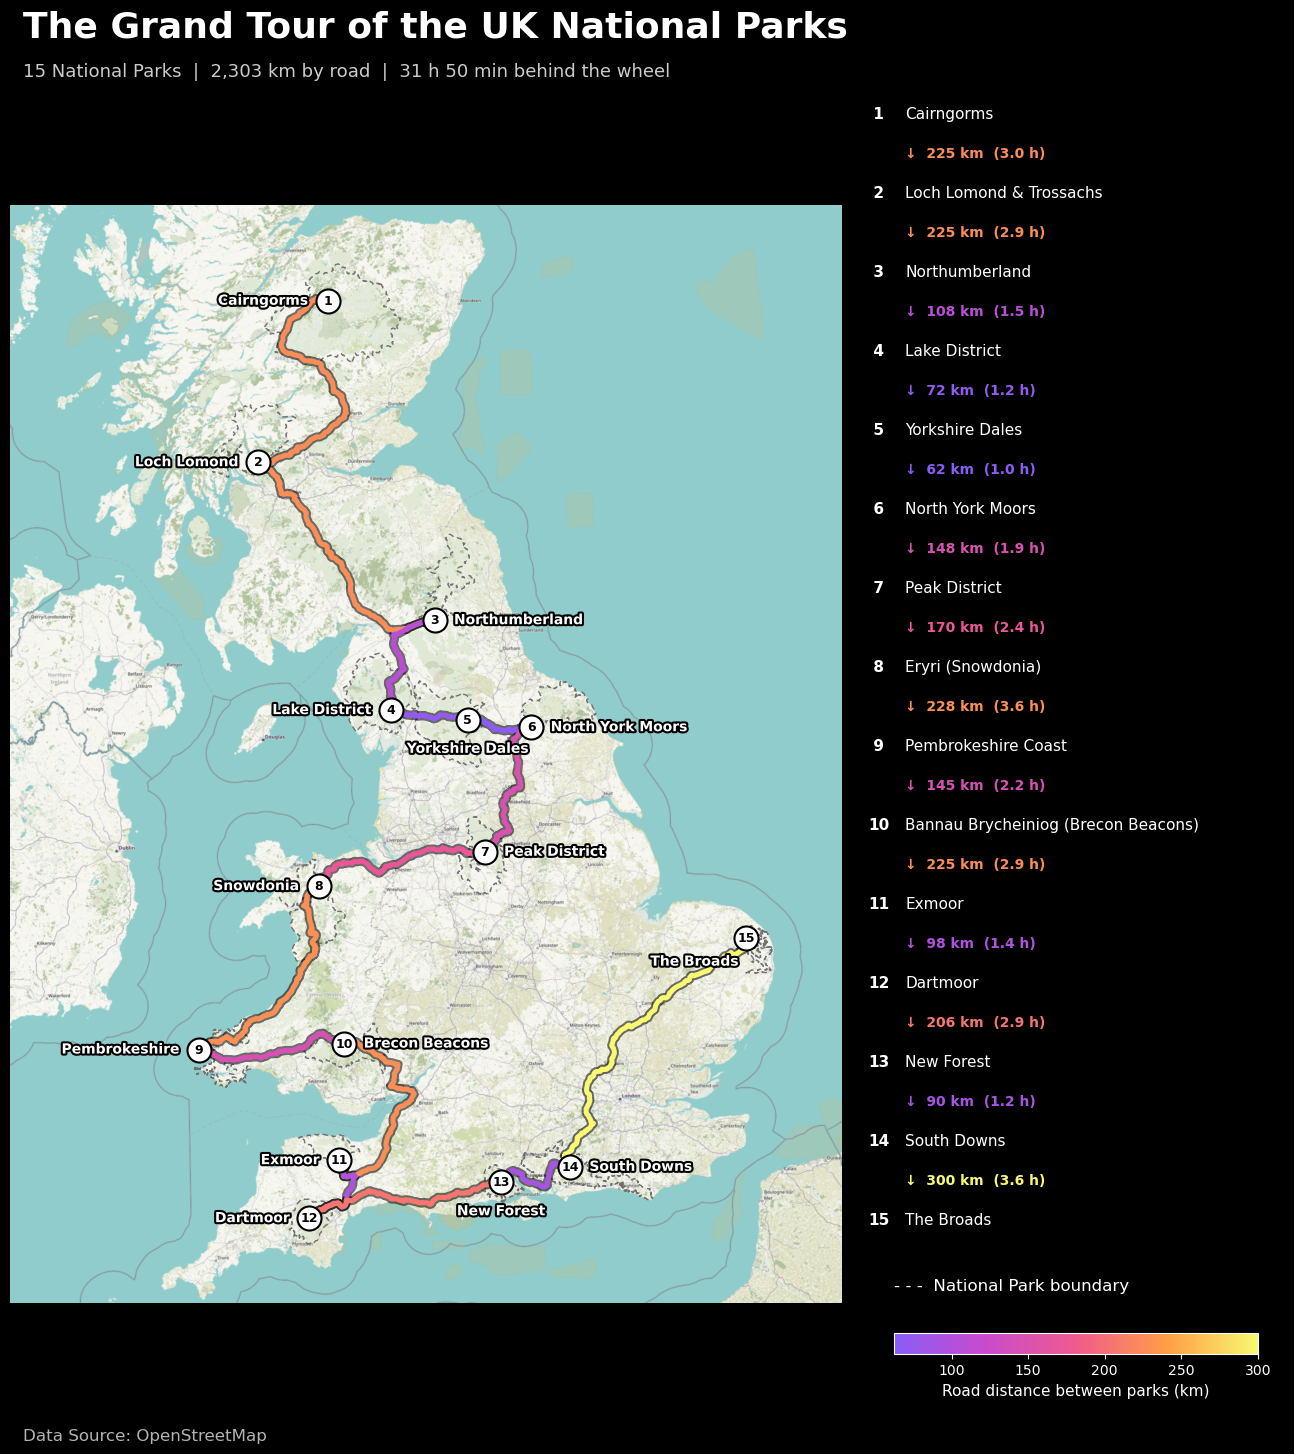

In [154]:
to_merc = Transformer.from_crs(4326, 3857, always_xy=True)

def project(lonlat):
    x, y = to_merc.transform(lonlat[:, 0], lonlat[:, 1])
    return np.column_stack([x, y])

def polygon_patch(poly, **kw):
    verts, codes = [], []
    for ring in [poly.exterior, *poly.interiors]:
        xy = np.asarray(ring.coords)
        verts.extend(xy)
        codes.extend([Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY])
    return PathPatch(Path(verts, codes), **kw)

segments = [project(l["line"]) for l in legs]
leg_km = np.array([l["km"] for l in legs])
norm = Normalize(vmin=leg_km.min(), vmax=leg_km.max())
cmap = plt.get_cmap(CMAP)

pts = project(np.array([[lon, lat] for lat, lon in coords]))   # in park order (PARKS list)
bnd = {park: transform(to_merc.transform, g) for park, g in boundaries.items()}

# Figure layout: map on the left, route list on the right
fig = plt.figure(figsize=(13, 15), facecolor=BG)
ax = fig.add_axes([0.01, 0.03, 0.64, 0.88])
ax.set_anchor("W")

# Extent covers the roads and the park boundaries
allxy = np.vstack(segments)
xmin, ymin = allxy.min(axis=0)
xmax, ymax = allxy.max(axis=0)
for g in bnd.values():
    bx0, by0, bx1, by1 = g.bounds
    xmin, ymin, xmax, ymax = min(xmin, bx0), min(ymin, by0), max(xmax, bx1), max(ymax, by1)
padx, pady = (xmax - xmin) * 0.12, (ymax - ymin) * 0.06
ax.set_xlim(xmin - padx * 2.6, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect("equal")
ax.axis("off")

ctx.add_basemap(ax, source=BASEMAP, zoom=ZOOM, attribution=False)

# National Park boundaries: dashed white line, no fill
for g in bnd.values():
    for p in polygons_of(g):
        ax.add_patch(polygon_patch(p, facecolor="none", edgecolor=BND, linewidth=1.0,
                                   linestyle=(0, (4, 3)), alpha=0.9, zorder=2))

# Route lines: casing first, then coloured leg on top
ax.add_collection(LineCollection(segments, colors=CASING, linewidths=6.5, alpha=0.55,
                                 capstyle="round", joinstyle="round", zorder=3))
lc = LineCollection(segments, cmap=cmap, norm=norm, linewidths=3.6,
                    capstyle="round", joinstyle="round", zorder=4)
lc.set_array(leg_km)
ax.add_collection(lc)

# Visitor centre points, numbered in trip order
rank = {park_idx: i + 1 for i, park_idx in enumerate(order)}
halo = [pe.withStroke(linewidth=3, foreground=BG)]
for i, (x, y) in enumerate(pts):
    ax.scatter(x, y, s=300, c="white", edgecolors="black", linewidths=1.5, zorder=6)
    ax.text(x, y, str(rank[i]), ha="center", va="center", fontsize=9,
            fontweight="bold", color="black", zorder=7)
    label = MAP_LABEL.get(names[i], names[i])
    if names[i] in LABEL_POS:
        dx, dy, ha, va = LABEL_POS[names[i]]
    elif coords[i][1] < -2.5:             # western parks: label on the left
        dx, dy, ha, va = -14, 0, "right", "center"
    else:
        dx, dy, ha, va = 14, 0, "left", "center"
    ax.annotate(label, (x, y), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, fontsize=10, color=FG, fontweight="bold",
                path_effects=halo, zorder=8)


# Title
fig.text(0.02, 0.955, "The Grand Tour of the UK National Parks", fontsize=26,
         fontweight="bold", color=FG, va="center")
fig.text(0.02, 0.925,
         f"{n} National Parks  |  {total_km:,.0f} km by road  |  {hm(total_h)} behind the wheel",
         fontsize=13, color=FG, alpha=0.8, va="center")

# Route list, each leg coloured like its line
ax_t = fig.add_axes([0.67, 0.12, 0.32, 0.79])
ax_t.axis("off")
ax_t.set_xlim(0, 1)
ax_t.set_ylim(0, 1)
rows = n + len(legs)
step = 1.0 / (rows + 1)
y = 1 - step * 0.5
for k, park_idx in enumerate(order):
    ax_t.text(0.0, y, f"{k + 1:>2}", fontsize=11, fontweight="bold", color=FG, va="center")
    ax_t.text(0.09, y, names[park_idx], fontsize=11, color=FG, va="center")
    y -= step
    if k < len(legs):
        c = cmap(norm(legs[k]["km"]))
        ax_t.text(0.09, y, f"\u2193  {legs[k]['km']:.0f} km  ({legs[k]['hours']:.1f} h)",
                  fontsize=10, color=c, fontweight="bold", va="center")
        y -= step

# Colourbar and boundary key
cax = fig.add_axes([0.69, 0.07, 0.28, 0.014])
cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
cb.set_label("Road distance between parks (km)", color=FG, fontsize=11)
cb.ax.xaxis.set_tick_params(color=FG, labelcolor=FG)
cb.outline.set_edgecolor(FG)
fig.text(0.69, 0.115, "- - -  National Park boundary", fontsize=12, color="white", va="center")

fig.text(0.02, 0.012,
         "Data Source: OpenStreetMap",
         fontsize=12, color=FG, alpha=0.7)

fig.savefig(OUT_PNG, dpi=200, facecolor=BG)
print("Saved", OUT_PNG)
plt.show()

## 9: Animated version
The camera starts zoomed in on park 1, follows a car along the real road route (it slows into each visitor centre and pauses briefly), then flies out to the full map.

Run Cells 1-8 first: this reuses `legs`, `order`, the boundaries and the helpers from the static map.

MP4 needs ffmpeg. If you don't have it: `pip install imageio-ffmpeg` (otherwise it falls back to a much larger GIF).

### 9a: Settings

In [157]:
# ---- Animation settings ----
ANIM_OUT        = "uk_national_parks_roadtrip.mp4"
ANIM_FPS        = 30
ANIM_SIZE       = (10.8, 13.5)   # inches; at ANIM_DPI = 100 this is 1080 x 1350 px (4:5, good for social)
ANIM_DPI        = 100
ANIM_ZOOM       = 9              # tile zoom for the close-up camera (10 is sharper but ~4x the tiles)
ANIM_ZOOM_FULL  = 7              # tile zoom for the zoomed-out view
# Basemaps are cached as anim_basemap_z*.npz after the first download; delete them to refetch

INTRO_SECONDS   = 1.0    # hold on park 1 before setting off
DRIVE_SECONDS   = 17     # total time spent driving, shared between legs by distance
STOP_SECONDS    = 0.35    # pause at each visitor centre
ZOOMOUT_SECONDS = 2.5    # pull back to the full map
OUTRO_SECONDS   = 2.0    # hold on the full map at the end

DRIVE_VIEW_KM   = 240    # width of the camera view while driving
STOP_VIEW_KM    = 130    # the camera tightens to this at each stop
CAR_SIZE        = 0.045  # car length as a share of the view width (so it stays the same size on screen)

### 9b: Plan the camera and car, frame by frame

In [159]:
MERC_R = 6378137.0

def merc_lat(y):
    """Latitude (degrees) of a Web Mercator y coordinate."""
    return np.degrees(2 * np.arctan(np.exp(y / MERC_R)) - np.pi / 2)

def km_to_merc(km, y):
    """Ground kilometres -> Web Mercator metres at the latitude of y."""
    return km * 1000.0 / np.cos(np.radians(merc_lat(y)))

leg_xy = [project(l["line"]) for l in legs]          # road geometry of each leg, Web Mercator
stop_xy = np.array([pts[i] for i in order])          # visitor centres in trip order

# Full-map view: same framing as the static map (extra room on the left for labels)
full_x0, full_x1 = xmin - padx * 2.6, xmax + padx
full_y0, full_y1 = ymin - pady, ymax + pady

fig_w, fig_h = ANIM_SIZE
MAP_BOX = [0.015, 0.035, 0.655, 0.86]                       # map axes position in the figure
view_ratio = (MAP_BOX[3] * fig_h) / (MAP_BOX[2] * fig_w)   # height / width of the map window

def ease(t):
    """Smooth start and stop (smootherstep)."""
    t = np.clip(t, 0, 1)
    return t * t * t * (t * (6 * t - 15) + 10)

def smooth(a, sigma):
    """Gaussian smoothing along the frame axis (no scipy needed)."""
    if sigma <= 0:
        return a.copy()
    r = int(3 * sigma)
    k = np.exp(-0.5 * (np.arange(-r, r + 1) / sigma) ** 2)
    k /= k.sum()
    pad = np.pad(a, (r, r), mode="edge")
    return np.convolve(pad, k, mode="valid")

# Cumulative distance along each leg's projected line, used to place the car
leg_cum = [np.concatenate([[0], np.cumsum(np.hypot(*np.diff(xy, axis=0).T))]) for xy in leg_xy]

def point_on_leg(k, d):
    """Position on leg k after d metres (Web Mercator), plus the index of the last full vertex."""
    cum, xy = leg_cum[k], leg_xy[k]
    d = np.clip(d, 0, cum[-1])
    j = int(np.searchsorted(cum, d, side="right") - 1)
    j = min(j, len(xy) - 2)
    f = (d - cum[j]) / max(cum[j + 1] - cum[j], 1e-9)
    return xy[j] + f * (xy[j + 1] - xy[j]), j

def heading_on_leg(k, d, look=4000.0):
    """Direction of travel (degrees) from a point a little behind to a little ahead."""
    p0, _ = point_on_leg(k, d - look)
    p1, _ = point_on_leg(k, d + look)
    v = p1 - p0
    return np.degrees(np.arctan2(v[1], v[0]))

# ---- Frame by frame plan: ("phase", leg, metres into leg) ----
fps = ANIM_FPS
plan = []
plan += [("intro", 0, 0.0)] * int(INTRO_SECONDS * fps)
drive_frames_total = DRIVE_SECONDS * fps
for k, leg in enumerate(legs):
    nf = max(12, int(round(drive_frames_total * leg["km"] / total_km)))
    L = leg_cum[k][-1]
    for f in range(1, nf + 1):
        plan.append(("drive", k, ease(f / nf) * L))
    plan += [("stop", k, L)] * int(STOP_SECONDS * fps)

N_follow = len(plan)
car_x, car_y, car_ang, view_km = (np.zeros(N_follow) for _ in range(4))
for i, (phase, k, d) in enumerate(plan):
    (car_x[i], car_y[i]), _ = point_on_leg(k, d)
    car_ang[i] = heading_on_leg(k, d)
    view_km[i] = STOP_VIEW_KM if phase in ("intro", "stop") else DRIVE_VIEW_KM

# Camera: smoothed version of the car path, with the zoom easing between drive and stop widths
car_ang = smooth(np.unwrap(np.radians(car_ang)), 0.15 * fps)
car_ang = np.degrees(car_ang)
cam_x = smooth(car_x, 0.35 * fps)
cam_y = smooth(car_y, 0.35 * fps)
cam_km = smooth(view_km, 0.6 * fps)
cam_w = km_to_merc(cam_km, cam_y)
follow_box = (np.min(cam_x - cam_w / 2), np.min(cam_y - cam_w * view_ratio / 2),
              np.max(cam_x + cam_w / 2), np.max(cam_y + cam_w * view_ratio / 2))

# ---- Fly out to the full map ----

full_w = full_x1 - full_x0
full_h = full_y1 - full_y0
if full_h / full_w > view_ratio:      # tall map: widen to fit the window
    full_w = full_h / view_ratio
full_cx, full_cy = (full_x0 + full_x1) / 2, (full_y0 + full_y1) / 2

w0, cx0, cy0 = cam_w[-1], cam_x[-1], cam_y[-1]
nz = int(ZOOMOUT_SECONDS * fps)
zoom_w, zoom_x, zoom_y = [], [], []
for f in range(1, nz + 1):
    e = ease(f / nz)
    w = np.exp(np.log(w0) + e * (np.log(full_w) - np.log(w0)))   # zoom evenly in log scale
    u = (w - w0) / (full_w - w0)                                 # pan in step with the zoom
    zoom_w.append(w)
    zoom_x.append(cx0 + u * (full_cx - cx0))
    zoom_y.append(cy0 + u * (full_cy - cy0))
n_out = int(OUTRO_SECONDS * fps)

cam_x = np.concatenate([cam_x, zoom_x, [full_cx] * n_out])
cam_y = np.concatenate([cam_y, zoom_y, [full_cy] * n_out])
cam_w = np.concatenate([cam_w, zoom_w, [full_w] * n_out])
last = plan[-1]
plan += [("zoomout", last[1], last[2])] * nz + [("outro", last[1], last[2])] * n_out
car_x = np.concatenate([car_x, [car_x[-1]] * (nz + n_out)])
car_y = np.concatenate([car_y, [car_y[-1]] * (nz + n_out)])
car_ang = np.concatenate([car_ang, [car_ang[-1]] * (nz + n_out)])

# The sharp close-up basemap fades out during the first 60% of the fly-out
hi_alpha = np.concatenate([np.ones(N_follow), 1 - ease(np.arange(1, nz + 1) / (0.6 * nz)), np.zeros(n_out)])

N_FRAMES = len(plan)
print(f"{N_FRAMES} frames = {N_FRAMES / fps:.1f} s at {fps} fps")

817 frames = 27.2 s at 30 fps


### 9c: Basemap for the animation
A sharp zoom-9 layer only where the close-up camera goes (~375 tiles) and a light zoom-7 layer for the full view (~35 tiles). Both are cached as `.npz` after the first run.

In [161]:
def fetch_basemap(x0, y0, x1, y1, zoom, cache):
    """Download (or load from cache) one basemap image covering a Web Mercator box."""
    if os.path.exists(cache):
        z = np.load(cache)
        img, ext = z["img"], tuple(z["ext"])
        print(f"zoom {zoom}: from cache, {img.shape[1]} x {img.shape[0]} px")
        return img, ext
    tile_m = 2 * np.pi * MERC_R / 2 ** zoom
    n_tiles = int(np.ceil((x1 - x0) / tile_m) + 1) * int(np.ceil((y1 - y0) / tile_m) + 1)
    print(f"zoom {zoom}: downloading about {n_tiles} tiles (one time only)...")
    img, ext = ctx.bounds2img(x0, y0, x1, y1, zoom=zoom, source=BASEMAP, ll=False)
    img = img[..., :3]
    np.savez_compressed(cache, img=img, ext=np.array(ext))
    print(f"zoom {zoom}: saved {cache}, {img.shape[1]} x {img.shape[0]} px")
    return img, ext

# Sharp layer: only where the close-up camera goes
hi_img, hi_ext = fetch_basemap(*follow_box, ANIM_ZOOM, f"anim_basemap_z{ANIM_ZOOM}.npz")
# Light layer: the whole fly-out view (the map is small on screen there, so zoom 7 is plenty)
fx0, fx1 = full_cx - full_w / 2, full_cx + full_w / 2
fy0, fy1 = full_cy - full_w * view_ratio / 2, full_cy + full_w * view_ratio / 2
lo_img, lo_ext = fetch_basemap(fx0, fy0, fx1, fy1, ANIM_ZOOM_FULL, f"anim_basemap_z{ANIM_ZOOM_FULL}.npz")

zoom 9: from cache, 3840 x 6144 px
zoom 7: from cache, 1024 x 1792 px


### 9d: Build the animated figure

In [163]:
from matplotlib.transforms import Affine2D
from matplotlib.patches import Circle

leg_col = [cmap(norm(l["km"])) for l in legs]
cum_km = np.concatenate([[0], np.cumsum([l["km"] for l in legs])])
cum_h = np.concatenate([[0], np.cumsum([l["hours"] for l in legs])])
short = lambda i: MAP_LABEL.get(names[i], names[i])

def crop_basemap(img, ext, x0, x1, y0, y1, max_px):
    """Cut the part of a big basemap that the camera sees (much faster than drawing it all)."""
    H, W = img.shape[:2]
    ex0, ex1, ey0, ey1 = ext
    px, py = (ex1 - ex0) / W, (ey1 - ey0) / H
    c0 = int(np.clip(np.floor((x0 - ex0) / px) - 2, 0, W - 1))
    c1 = int(np.clip(np.ceil((x1 - ex0) / px) + 2, c0 + 1, W))
    r0 = int(np.clip(np.floor((ey1 - y1) / py) - 2, 0, H - 1))
    r1 = int(np.clip(np.ceil((ey1 - y0) / py) + 2, r0 + 1, H))
    s = max(1, (c1 - c0) // max_px)            # skip pixels if far more than the screen needs
    c1 = c0 + (c1 - c0) // s * s
    r1 = r0 + (r1 - r0) // s * s
    return img[r0:r1:s, c0:c1:s], (ex0 + c0 * px, ex0 + c1 * px, ey1 - r1 * py, ey1 - r0 * py)

# Car shape, pointing along +x, length 1 (scaled to the view each frame)
CAR_BODY = Path([(-0.5, -0.22), (0.36, -0.22), (0.5, -0.13), (0.5, 0.13), (0.36, 0.22),
                 (-0.5, 0.22), (-0.5, -0.22)], closed=True)
CAR_GLASS = Path([(0.10, -0.16), (0.27, -0.14), (0.27, 0.14), (0.10, 0.16), (0.10, -0.16)], closed=True)
CAR_REAR = Path([(-0.42, -0.15), (-0.33, -0.15), (-0.33, 0.15), (-0.42, 0.15), (-0.42, -0.15)], closed=True)

def build_anim_figure():
    fig = plt.figure(figsize=ANIM_SIZE, dpi=ANIM_DPI, facecolor=BG)
    ax = fig.add_axes(MAP_BOX)
    ax.set_facecolor(BG)
    ax.axis("off")
    ax.imshow(lo_img, extent=lo_ext, interpolation="antialiased", zorder=0)
    hi = ax.imshow(hi_img[:2, :2], extent=hi_ext, interpolation="antialiased", zorder=0.5)
    map_px = int(MAP_BOX[2] * ANIM_SIZE[0] * ANIM_DPI)    # map width on screen, in pixels

    for g in bnd.values():
        for p in polygons_of(g):
            ax.add_patch(polygon_patch(p, facecolor="none", edgecolor=BND, linewidth=1.0,
                                       linestyle=(0, (4, 3)), alpha=0.9, zorder=2))

    # The whole route, faint, so you can see where the car is heading
    ax.add_collection(LineCollection(leg_xy, colors="white", linewidths=2.2, alpha=0.35,
                                     linestyles=(0, (2, 2)), zorder=3))
    # The trail driven so far (updated every frame)
    trail_case = LineCollection([], colors=CASING, linewidths=6.5, alpha=0.55,
                                capstyle="round", joinstyle="round", zorder=4)
    trail = LineCollection([], linewidths=3.6, capstyle="round", joinstyle="round", zorder=5)
    ax.add_collection(trail_case)
    ax.add_collection(trail)

    # Stops in trip order: grey until reached, then white
    stops = ax.scatter(stop_xy[:, 0], stop_xy[:, 1], s=300, c="#8a8a8a",
                       edgecolors="black", linewidths=1.5, zorder=7)
    labels = []
    for k, i in enumerate(order):
        x, y = stop_xy[k]
        ax.text(x, y, str(k + 1), ha="center", va="center", fontsize=9,
                fontweight="bold", color="black", zorder=8)
        if names[i] in LABEL_POS:
            dx, dy, ha, va = LABEL_POS[names[i]]
        elif coords[i][1] < -2.5:
            dx, dy, ha, va = -14, 0, "right", "center"
        else:
            dx, dy, ha, va = 14, 0, "left", "center"
        labels.append(ax.annotate(short(i), (x, y), xytext=(dx, dy), textcoords="offset points",
                                  ha=ha, va=va, fontsize=11, color=FG, fontweight="bold",
                                  path_effects=halo, zorder=8))

    # The car: soft glow, body, windscreen and rear window
    glow = Circle((0, 0), 0.75, facecolor="white", edgecolor="none", alpha=0.25, zorder=9)
    body = PathPatch(CAR_BODY, facecolor="white", edgecolor="black", linewidth=1.4, zorder=10)
    glass = PathPatch(CAR_GLASS, facecolor="#1b1b2f", edgecolor="none", zorder=11)
    rear = PathPatch(CAR_REAR, facecolor="#1b1b2f", edgecolor="none", zorder=11)
    car = [glow, body, glass, rear]
    for p in car:
        ax.add_patch(p)

    # Odometer / status box on the map
    hud = ax.text(0.03, 0.975, "", transform=ax.transAxes, ha="left", va="top", fontsize=13,
                  color=FG, fontweight="bold", linespacing=1.5, zorder=20,
                  bbox=dict(boxstyle="round,pad=0.6", facecolor="black", edgecolor="#444", alpha=0.8))

    # Title
    fig.text(0.02, 0.962, "The Grand Tour of the UK National Parks", fontsize=24,
             fontweight="bold", color=FG, va="center")
    fig.text(0.02, 0.928,
             f"{n} National Parks  |  {total_km:,.0f} km by road  |  {hm(total_h)} behind the wheel",
             fontsize=13, color=FG, alpha=0.8, va="center")

    # Route list on the right; rows light up as the trip progresses
    ax_t = fig.add_axes([0.69, 0.14, 0.30, 0.76])
    ax_t.axis("off")
    ax_t.set_xlim(0, 1)
    ax_t.set_ylim(0, 1)
    step = 1.0 / (n + len(legs) + 1)
    yy = 1 - step * 0.5
    park_rows, leg_rows = [], []
    for k, i in enumerate(order):
        a = ax_t.text(0.0, yy, f"{k + 1:>2}", fontsize=12, fontweight="bold", color=FG, va="center")
        b = ax_t.text(0.12, yy, short(i), fontsize=12, color=FG, va="center")
        park_rows.append((a, b))
        yy -= step
        if k < len(legs):
            leg_rows.append(ax_t.text(0.12, yy, f"↓  {legs[k]['km']:.0f} km  ({legs[k]['hours']:.1f} h)",
                                      fontsize=11, color=leg_col[k], fontweight="bold", va="center"))
            yy -= step

    cax = fig.add_axes([0.70, 0.075, 0.27, 0.013])
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
    cb.set_label("Road distance between parks (km)", color=FG, fontsize=11)
    cb.ax.xaxis.set_tick_params(color=FG, labelcolor=FG)
    cb.outline.set_edgecolor(FG)
    fig.text(0.70, 0.115, "- - -  National Park boundary", fontsize=11, color=FG, va="center")
    fig.text(0.02, 0.012, "Data Source: OpenStreetMap  |  Routing: OSRM", fontsize=11, color=FG, alpha=0.7)

    art = dict(ax=ax, trail=trail, trail_case=trail_case, stops=stops, labels=labels, car=car,
               hud=hud, park_rows=park_rows, leg_rows=leg_rows)

    def update(i):
        phase, k, d = plan[i]
        # Camera
        w = cam_w[i]
        h = w * view_ratio
        ax.set_xlim(cam_x[i] - w / 2, cam_x[i] + w / 2)
        ax.set_ylim(cam_y[i] - h / 2, cam_y[i] + h / 2)

        hi.set_visible(hi_alpha[i] > 0.01)
        if hi.get_visible():
            data, ext = crop_basemap(hi_img, hi_ext, cam_x[i] - w / 2, cam_x[i] + w / 2,
                                     cam_y[i] - h / 2, cam_y[i] + h / 2, 2 * map_px)
            hi.set_data(data)
            hi.set_extent(ext)
            hi.set_alpha(hi_alpha[i])

        # How far along are we?
        if phase == "intro":
            done_legs, partial = 0, None
        elif phase == "drive":
            done_legs, partial = k, d
        else:                                   # stop / zoomout / outro: leg k finished
            done_legs, partial = k + 1, None

        segs = [leg_xy[j] for j in range(done_legs)]
        cols = leg_col[:done_legs]
        if partial is not None and partial > 0:
            p, j = point_on_leg(k, partial)
            segs.append(np.vstack([leg_xy[k][:j + 1], p]))
            cols = cols + [leg_col[k]]
        trail.set_segments(segs)
        trail.set_color(cols)
        trail_case.set_segments(segs)

        # Stops reached so far
        reached = done_legs + 1
        fc = np.array([[1, 1, 1, 1]] * reached + [[0.54, 0.54, 0.54, 1]] * (n - reached))
        stops.set_facecolors(fc)
        for s, lab in enumerate(labels):
            lab.set_alpha(1.0 if s < reached else 0.55)

        # Car: same size on screen whatever the zoom
        L = w * CAR_SIZE
        tr = Affine2D().scale(L).rotate_deg(car_ang[i]).translate(car_x[i], car_y[i]) + ax.transData
        col = leg_col[min(k, len(legs) - 1)]
        car[0].set_facecolor(col)
        car[1].set_facecolor(col)
        for p in car:
            p.set_transform(tr)

        # Status box
        if phase == "intro":
            hud.set_text(f"Setting off from\n{short(order[0])}")
        elif phase == "drive":
            frac = d / leg_cum[k][-1]
            km_now = cum_km[k] + frac * legs[k]["km"]
            h_now = cum_h[k] + frac * legs[k]["hours"]
            hud.set_text(f"Leg {k + 1} of {len(legs)}:  {short(order[k])} → {short(order[k + 1])}\n"
                         f"{km_now:,.0f} km  |  {hm(h_now)}")
        elif phase == "stop":
            hud.set_text(f"Stop {k + 2} of {n}:  {short(order[k + 1])}\n"
                         f"{cum_km[k + 1]:,.0f} km  |  {hm(cum_h[k + 1])}")
        else:
            hud.set_text(f"All {n} parks visited\n{total_km:,.0f} km  |  {hm(total_h)}")

        # Route list
        for s, (a, b) in enumerate(park_rows):
            on = s < reached
            a.set_alpha(1.0 if on else 0.3)
            b.set_alpha(1.0 if on else 0.3)
            b.set_fontweight("bold" if (phase in ("intro", "stop") and s == reached - 1) else "normal")
        for s, t in enumerate(leg_rows):
            t.set_alpha(1.0 if s < done_legs or (phase == "drive" and s == k) else 0.3)

    return fig, update

### 9e: Preview a few frames (fast, check the framing before rendering)

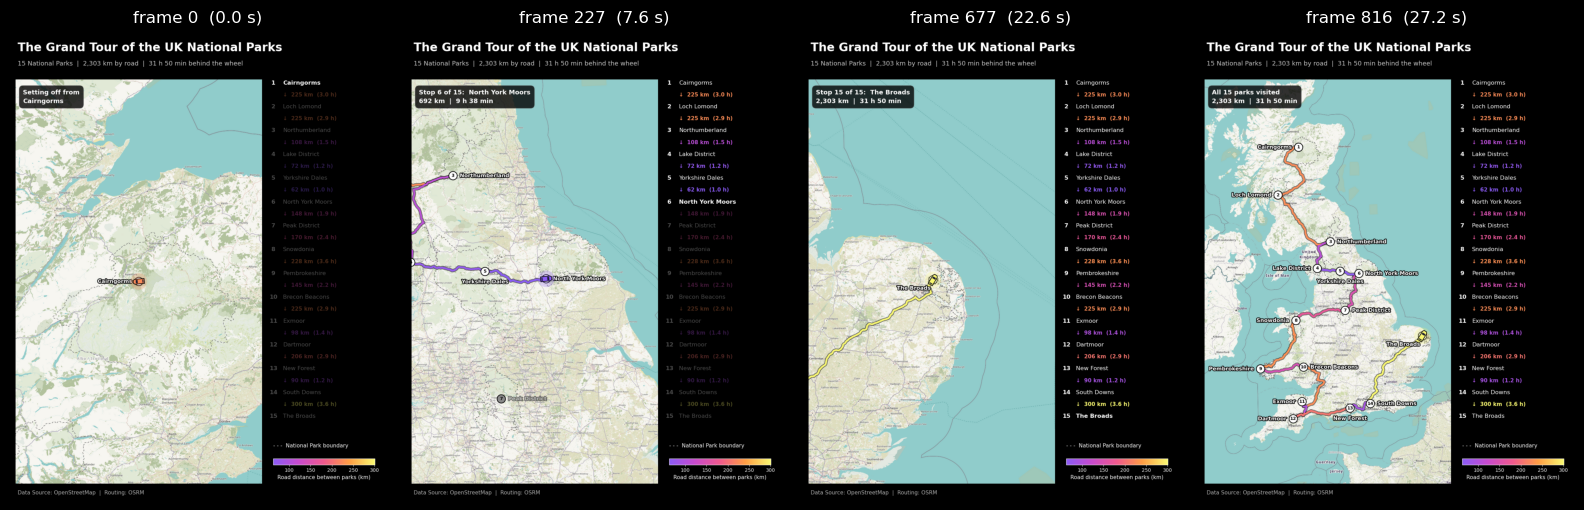

In [165]:
# Quick check of the framing before the full render: a few key frames side by side
fig, update = build_anim_figure()
picks = [0, N_follow // 3, N_follow - int(STOP_SECONDS * fps) // 2, N_FRAMES - 1]
stills = []
for i in picks:
    update(i)
    fig.canvas.draw()
    stills.append(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
plt.close(fig)

fig_p, axs = plt.subplots(1, len(stills), figsize=(4 * len(stills), 5), facecolor=BG)
for a, img, i in zip(axs, stills, picks):
    a.imshow(img)
    a.set_title(f"frame {i}  ({i / fps:.1f} s)", color=FG)
    a.axis("off")
plt.tight_layout()
plt.show()

### 9f: Render the video
About 820 frames (27 s). Takes roughly 3-4 minutes.

In [167]:
import shutil
from matplotlib.animation import FFMpegWriter, PillowWriter
from IPython.display import Video, Image, display

# Use the system ffmpeg, or the one bundled with imageio-ffmpeg (pip install imageio-ffmpeg)
if not shutil.which(plt.rcParams["animation.ffmpeg_path"]):
    try:
        import imageio_ffmpeg
        plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    except ImportError:
        pass

if FFMpegWriter.isAvailable() or shutil.which(plt.rcParams["animation.ffmpeg_path"]):
    out = ANIM_OUT
    writer = FFMpegWriter(fps=fps, codec="libx264",
                          extra_args=["-pix_fmt", "yuv420p", "-crf", "20", "-preset", "veryfast"])
else:
    out = os.path.splitext(ANIM_OUT)[0] + ".gif"
    print("ffmpeg not found, writing a GIF instead (much larger). `pip install imageio-ffmpeg` for MP4.")
    writer = PillowWriter(fps=fps)

fig, update = build_anim_figure()
t0 = time.time()
with writer.saving(fig, out, dpi=ANIM_DPI):
    for i in range(N_FRAMES):
        update(i)
        writer.grab_frame(facecolor=BG)
        if i % 100 == 0 or i == N_FRAMES - 1:
            el = time.time() - t0
            print(f"\r  frame {i + 1}/{N_FRAMES}  ({el:.0f} s elapsed, ~{el / (i + 1) * (N_FRAMES - i - 1):.0f} s left)",
                  end="")
plt.close(fig)
print(f"\nSaved {out}")

display(Video(out, width=540) if out.endswith(".mp4") else Image(out, width=540))

  frame 817/817  (102 s elapsed, ~0 s left)
Saved uk_national_parks_roadtrip.mp4
